In [43]:
import numpy as np
import pandas as pd

In [44]:
data ="https://huggingface.co/datasets/DElmazi/Student_Performance/resolve/main/student-mat.csv"
!wget $data

--2026-10-22 18:19:20--  https://huggingface.co/datasets/DElmazi/Student_Performance/resolve/main/student-mat.csv
Resolving huggingface.co (huggingface.co)... 18.239.50.80, 18.239.50.49, 18.239.50.103, ...
Connecting to huggingface.co (huggingface.co)|18.239.50.80|:443... connected.
HTTP request sent, awaiting response... 307 Temporary Redirect
Location: /api/resolve-cache/datasets/DElmazi/Student_Performance/85a4fba73197d748e4cfd445a5e9c2ed35ca4a21/student-mat.csv?%2Fdatasets%2FDElmazi%2FStudent_Performance%2Fresolve%2Fmain%2Fstudent-mat.csv=&etag=%2258efc299b2d614206eedb2ec7c9c751737ac7afe%22 [following]
--2026-10-22 18:19:20--  https://huggingface.co/api/resolve-cache/datasets/DElmazi/Student_Performance/85a4fba73197d748e4cfd445a5e9c2ed35ca4a21/student-mat.csv?%2Fdatasets%2FDElmazi%2FStudent_Performance%2Fresolve%2Fmain%2Fstudent-mat.csv=&etag=%2258efc299b2d614206eedb2ec7c9c751737ac7afe%22
Reusing existing connection to huggingface.co:443.
HTTP request sent, awaiting response... 200

In [45]:
df = pd.read_csv(data, sep=";")
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [46]:
df.columns

Index(['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu',
       'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime',
       'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery',
       'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc',
       'Walc', 'health', 'absences', 'G1', 'G2', 'G3'],
      dtype='str')

In [47]:
df.dtypes

school          str
sex             str
age           int64
address         str
famsize         str
Pstatus         str
Medu          int64
Fedu          int64
Mjob            str
Fjob            str
reason          str
guardian        str
traveltime    int64
studytime     int64
failures      int64
schoolsup       str
famsup          str
paid            str
activities      str
nursery         str
higher          str
internet        str
romantic        str
famrel        int64
freetime      int64
goout         int64
Dalc          int64
Walc          int64
health        int64
absences      int64
G1            int64
G2            int64
G3            int64
dtype: object

In [48]:
df.columns = df.columns.str.lower().str.replace(' ', '_')

In [49]:
strings = list(df.dtypes[df.dtypes == 'str'].index)

In [50]:
for col in strings :
    df[col] = df[col].str.lower().str.replace(' ','_')

In [51]:
df.head()

,school,sex,age,address,famsize,pstatus,medu,fedu,mjob,fjob,...,famrel,freetime,goout,dalc,walc,health,absences,g1,g2,g3
0,gp,f,18,u,gt3,a,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,gp,f,17,u,gt3,t,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,gp,f,15,u,le3,t,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,gp,f,15,u,gt3,t,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,gp,f,16,u,gt3,t,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [52]:
for col in df.columns:
    print(col)
    print(df[col].unique()[:5])
    print(df[col].nunique())
    print()

school
<StringArray>
['gp', 'ms']
Length: 2, dtype: str
2

sex
<StringArray>
['f', 'm']
Length: 2, dtype: str
2

age
[18 17 15 16 19]
8

address
<StringArray>
['u', 'r']
Length: 2, dtype: str
2

famsize
<StringArray>
['gt3', 'le3']
Length: 2, dtype: str
2

pstatus
<StringArray>
['a', 't']
Length: 2, dtype: str
2

medu
[4 1 3 2 0]
5

fedu
[4 1 2 3 0]
5

mjob
<StringArray>
['at_home', 'health', 'other', 'services', 'teacher']
Length: 5, dtype: str
5

fjob
<StringArray>
['teacher', 'other', 'services', 'health', 'at_home']
Length: 5, dtype: str
5

reason
<StringArray>
['course', 'other', 'home', 'reputation']
Length: 4, dtype: str
4

guardian
<StringArray>
['mother', 'father', 'other']
Length: 3, dtype: str
3

traveltime
[2 1 3 4]
4

studytime
[2 3 1 4]
4

failures
[0 3 2 1]
4

schoolsup
<StringArray>
['yes', 'no']
Length: 2, dtype: str
2

famsup
<StringArray>
['no', 'yes']
Length: 2, dtype: str
2

paid
<StringArray>
['no', 'yes']
Length: 2, dtype: str
2

activities
<StringArray>
['no', '

In [53]:
df['g3'].values

array([ 6,  6, 10, 15, 10, 15, 11,  6, 19, 15,  9, 12, 14, 11, 16, 14, 14,
       10,  5, 10, 15, 15, 16, 12,  8,  8, 11, 15, 11, 11, 12, 17, 16, 12,
       15,  6, 18, 15, 11, 13, 11, 12, 18, 11,  9,  6, 11, 20, 14,  7, 13,
       13, 10, 11, 13, 10, 15, 15,  9, 16, 11, 11,  9,  9, 10, 15, 12,  6,
        8, 16, 15, 10,  5, 14, 11, 10, 10, 11, 10,  5, 12, 11,  6, 15, 10,
        8,  6, 14, 10,  7,  8, 18,  6, 10, 14, 10, 15, 10, 14,  8,  5, 17,
       14,  6, 18, 11,  8, 18, 13, 16, 19, 10, 13, 19,  9, 16, 14, 13,  8,
       13, 15, 15, 13, 13,  8, 12, 11,  9,  0, 18,  0,  0, 12, 11,  0,  0,
        0,  0, 12, 15,  0,  9, 11, 13,  0, 11,  0, 11,  0, 10,  0, 14, 10,
        0, 12,  8, 13, 10, 15, 12,  0,  7,  0, 10,  7, 12, 10, 16,  0, 14,
        0, 16, 10,  0,  9,  9, 11,  6,  9, 11,  8, 12, 17,  8, 12, 11, 11,
       15,  9, 10, 13,  9,  8, 10, 14, 15, 16, 10, 18, 10, 16, 10, 10,  6,
       11,  9,  7, 13, 10,  7,  8, 13, 14,  8, 10, 15,  4,  8,  8, 10,  6,
        0, 17, 13, 14,  7

In [54]:
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

<Axes: xlabel='g3', ylabel='Count'>

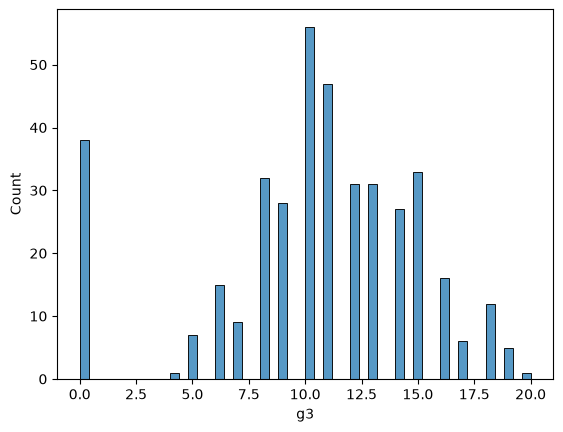

In [55]:
sns.histplot(df['g3'],bins=50)

In [56]:
df.isnull().sum()

school        0
sex           0
age           0
address       0
famsize       0
pstatus       0
medu          0
fedu          0
mjob          0
fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
dalc          0
walc          0
health        0
absences      0
g1            0
g2            0
g3            0
dtype: int64

In [57]:
df = df[df.g3 != 0]

In [58]:
n = len(df)
n_test = int(len(df)*0.2)
n_val = int(len(df)*0.2)
n_train = n - n_test -n_val

In [59]:
df_train = df.iloc[:n_train]
df_val = df.iloc[n_train : n_train+n_val]
df_test = df.iloc[n_train+n_val:]

In [60]:
idx = np.arange(n)

In [61]:
np.random.seed(2)
np.random.shuffle(idx)

In [62]:
df_train = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train:n_train+n_val]]
df_test = df.iloc[idx[n_train+n_val:]]

In [63]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [65]:
y_train = df_train.g3.values
y_val = df_val.g3.values
y_test = df_test.g3.values

In [66]:
del df_train['g3']
del df_val['g3']
del df_test['g3']

In [67]:
Base = ['age', 'absences', 'g1', 'g2']

In [68]:
X_train = df_train[Base].values

In [69]:
def train_linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)

    return w_full[0], w_full[1:]

In [70]:
train_linear_regression(X_train, y_train)

(np.float64(-0.2976570788912303),
 array([ 0.03629887, -0.01393233,  0.15057826,  0.84881689]))

In [72]:
w0, w = train_linear_regression(X_train, y_train)
w0, w

(np.float64(-0.2976570788912303),
 array([ 0.03629887, -0.01393233,  0.15057826,  0.84881689]))

In [73]:
y_pred = w0+X_train.dot(w)

<Axes: ylabel='Count'>

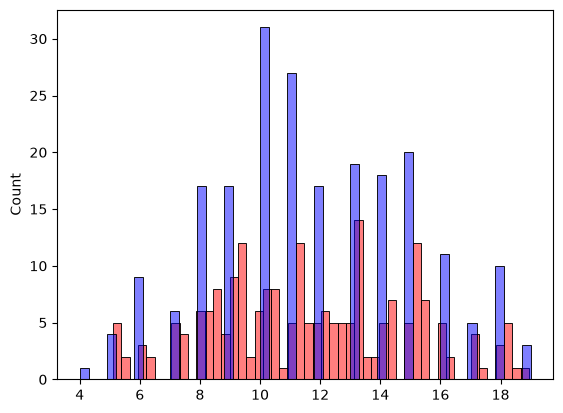

In [74]:
sns.histplot(y_pred, color='red',alpha=0.5,bins=50)
sns.histplot(y_train, color='blue',alpha=0.5,bins=50)

In [75]:
def rmse(y,y_pred):
    error = y-y_pred
    se = error**2
    mse = se.mean()
    return np.sqrt(mse)

In [76]:
rmse(y_train , y_pred)

np.float64(0.8201030749341226)

In [77]:
def prepare_X(df):
    df_num = df[Base]
    df_num = df_num.fillna(0)
    X = df_num.values
    return X

In [78]:
X_train = prepare_X(df_train)
w0, w = train_linear_regression(X_train, y_train)

X_val = prepare_X(df_val)
y_pred = w0 + X_val.dot(w)
rmse(y_val, y_pred)

np.float64(0.7369932953629448)

In [80]:
categorical_variables = [
    'school',
    'sex',
    'address',
    'famsize',
    'pstatus',
    'mjob',
    'fjob',
    'reason',
    'guardian',
    'schoolsup',
    'famsup',
    'paid',
    'activities',
    'nursery',
    'higher',
    'internet',
    'romantic'
]

In [81]:
categories = {}
categories = {}
for c in categorical_variables:
    categories[c] = list(df_train[c].value_counts().head().index)

In [82]:
categories

{'school': ['gp', 'ms'],
 'sex': ['f', 'm'],
 'address': ['u', 'r'],
 'famsize': ['gt3', 'le3'],
 'pstatus': ['t', 'a'],
 'mjob': ['other', 'services', 'teacher', 'at_home', 'health'],
 'fjob': ['other', 'services', 'teacher', 'health', 'at_home'],
 'reason': ['course', 'reputation', 'home', 'other'],
 'guardian': ['mother', 'father', 'other'],
 'schoolsup': ['no', 'yes'],
 'famsup': ['yes', 'no'],
 'paid': ['yes', 'no'],
 'activities': ['yes', 'no'],
 'nursery': ['yes', 'no'],
 'higher': ['yes', 'no'],
 'internet': ['yes', 'no'],
 'romantic': ['no', 'yes']}

In [83]:
def prepare_X(df):
    df = df.copy()
    features = Base.copy()
    
    for name, values in categories.items():
        for value in values:
            df['%s_%s' % (name, value)] = (df[name] == value).astype('int')
            features.append('%s_%s' % (name, value))

    df_num = df[features]
    df_num = df_num.fillna(0)
    X = df_num.values
    
    return X

In [84]:
X_train = prepare_X(df_train)
w0, w = train_linear_regression(X_train, y_train)

X_val = prepare_X(df_val)
y_pred = w0 + X_val.dot(w)

rmse(y_val, y_pred)

np.float64(374.82593143116367)

In [85]:
def train_linear_regression_reg(X, y , r= 0.001):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX = XTX + r * np.eye(XTX.shape[0])
    
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)

    return w_full[0], w_full[1:]

In [88]:
for r in [0.0 , 0.00001 , 0.0001 , 0.001 , 0.1 , 1 , 10 ,20,30,40,50, 60,70,80, 100, 1000 ]:
    X_train = prepare_X(df_train)
    w0, w = train_linear_regression_reg(X_train, y_train , r=r)
    
    X_val = prepare_X(df_val)
    y_pred = w0 + X_val.dot(w)
    score = rmse(y_val, y_pred)
    print(r,w0,score)

0.0 2.2240088002751075e+17 374.82593143116367
1e-05 -0.20376837394542235 0.8170914892384723
0.0001 -0.15365471064239955 0.8170907754160031
0.001 -0.15349529876759505 0.8170836580406021
0.1 -0.1493708077868402 0.8163152169941582
1 -0.11922773334332878 0.8103856640732217
10 -0.031253188588441665 0.7842626848553916
20 -0.012103545704129337 0.7737630229800767
30 -0.004707339586993636 0.7694571553044308
40 -0.0008843085567898773 0.768103468427988
50 0.0014110865912909478 0.76838338894264
60 0.0029215965400764326 0.7696426709227222
70 0.003979248103820289 0.7715181721122804
80 0.004753902477998045 0.7737925729526566
100 0.005798614023161859 0.7790360128533624
1000 0.010411592126966632 0.9805083932679075


In [89]:
r = 40
X_train = prepare_X(df_train)
w0, w = train_linear_regression_reg(X_train, y_train , r=r)
    
X_val = prepare_X(df_val)
y_pred = w0 + X_val.dot(w)
score = rmse(y_val, y_pred)
score

np.float64(0.768103468427988)

In [90]:
df_full_train = pd.concat([df_train, df_val])

In [91]:
df_full_train = df_full_train.reset_index(drop=True)

In [92]:
X_full_train = prepare_X(df_full_train)

In [93]:
y_full_train = np.concatenate([y_train, y_val])
y_full_train

array([ 8, 15, 10,  8, 10, 15, 18, 10, 16,  8, 15,  8, 10, 11, 13,  6, 10,
       12, 15, 12,  7, 10, 10,  4, 10, 14, 10, 10,  8,  9,  7,  9, 14, 10,
       12,  7, 13,  9, 10,  9, 15, 13, 13, 15, 14, 10, 18,  5, 11,  9, 10,
       13, 14, 11,  6, 12, 14, 12, 12, 11, 15, 10, 11, 16, 18, 10, 18,  6,
       17, 11,  9, 16,  6,  8, 11, 13, 12, 13, 15, 14, 14, 15, 19, 11,  9,
       15, 13,  8, 12, 12, 11, 16, 11, 10,  9, 14, 13, 13, 11, 12, 10,  8,
        8, 14, 11, 10,  8, 18, 14, 11, 14, 12, 12, 11, 19,  8,  7, 17,  9,
       13, 10,  6, 11, 18,  9, 13,  8,  8, 13, 10, 18,  9,  7,  8, 12, 11,
       10, 11,  9, 14, 10, 18, 13, 14, 10, 16, 14, 15,  5, 11, 16, 11, 12,
        6, 10, 16, 12, 15, 11, 10,  9,  9, 19, 11, 10, 10, 17,  9, 15, 11,
       11,  5, 10, 16, 12, 10, 13, 15, 16, 14, 12, 11, 13,  8, 15,  5, 17,
        8, 15, 15,  7,  6, 17, 13, 11, 16, 18, 14, 18,  9,  6, 15,  8, 15,
       13, 14, 11,  9, 16, 11, 10, 15, 13,  6, 14, 10, 12, 13, 18, 19, 11,
       11,  9, 10,  7,  8

In [95]:
w0, w = train_linear_regression_reg(X_full_train, y_full_train , r=40)

In [96]:
X_test = prepare_X(df_test)
y_pred = w0 + X_test.dot(w)
score = rmse(y_test, y_pred)
score

np.float64(0.9468029807319823)

In [97]:
df_test.iloc[20]

school                gp
sex                    f
age                   17
address                r
famsize              gt3
pstatus                t
medu                   2
fedu                   2
mjob               other
fjob               other
reason        reputation
guardian          mother
traveltime             1
studytime              1
failures               0
schoolsup             no
famsup               yes
paid                  no
activities            no
nursery              yes
higher               yes
internet             yes
romantic              no
famrel                 5
freetime               3
goout                  2
dalc                   1
walc                   2
health                 3
absences              18
g1                     7
g2                     6
Name: 20, dtype: object

In [98]:
stdu = df_test.iloc[20].to_dict()
stdu

{'school': 'gp',
 'sex': 'f',
 'age': 17,
 'address': 'r',
 'famsize': 'gt3',
 'pstatus': 't',
 'medu': 2,
 'fedu': 2,
 'mjob': 'other',
 'fjob': 'other',
 'reason': 'reputation',
 'guardian': 'mother',
 'traveltime': 1,
 'studytime': 1,
 'failures': 0,
 'schoolsup': 'no',
 'famsup': 'yes',
 'paid': 'no',
 'activities': 'no',
 'nursery': 'yes',
 'higher': 'yes',
 'internet': 'yes',
 'romantic': 'no',
 'famrel': 5,
 'freetime': 3,
 'goout': 2,
 'dalc': 1,
 'walc': 2,
 'health': 3,
 'absences': 18,
 'g1': 7,
 'g2': 6}

In [99]:
df_small = pd.DataFrame([stdu])
df_small

,school,sex,age,address,famsize,pstatus,medu,fedu,mjob,fjob,...,romantic,famrel,freetime,goout,dalc,walc,health,absences,g1,g2
0,gp,f,17,r,gt3,t,2,2,other,other,...,no,5,3,2,1,2,3,18,7,6


In [100]:
X_small = prepare_X(df_small)

In [101]:
y_small_pred = w0 + X_small.dot(w)
y_small_pred =y_small_pred[0]
y_small_pred

np.float64(6.390665242297825)

In [102]:
y_test[20]

np.int64(6)